<a href="https://colab.research.google.com/github/cnix17/STAT-7110-Quality-Control/blob/main/Assignments/HW1/STAT-7110-HW1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Homework 1 - Phase I & II Analysis Using Shewhart $\bar{X}$ and R/s Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: September 19, 2026 via D2L**

## Instructions:

A company called Blue Ridge Filament Co (BRFC) manufactures 1.75 mm PLA filament for 3D printers, selling to both hobbyist and small-manufacturing customers. Over the last quarter, customer support tickets describing clogging, stringing, and inconsistent print layers have risen sharply, and BRFC recently lost a wholesale account to a competitor over “inconsistent quality.” The plant manager has asked your quality control team to investigate Extruder Line 3, the line most frequently named in the complaint data, and to determine whether the line is running in a state of statistical control. This line is about six months away from needing its heating element replaced, but it could be replaced sooner if necessary.

The plant manager is particularly interested in the filament diameter produced (mm), measured inline by a laser micrometer as each spool is produced. Diameter that runs too thin causes under-extrusion and stringing; diameter that runs too thick causes jams and clogs in customers' print heads. Filament diameter is treated as a continuous, normally-distributed quality characteristic for this assignment.

Your team pulls a baseline (Phase I) sample of production data from Line 3: 5 spools sampled at random each week, for 25 consecutive weeks. After validating statistical control and process capability, the team can establish an ongoing monitoring plan for Phase II analysis.

## Key Specifications

| Quantity | Value |
|---|---|
| Target diameter | 1.750 mm |
| Lower Specification Limit (LSL) | 1.700 mm |
| Upper Specification Limit (USL) | 1.800 mm |
| Subgroup size (n) | 5 spools per week |
| Phase I subgroups (m) | 25 weeks |
| Phase II subgroups | 20 weeks |

In [1]:
## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "cnix17"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}

In [2]:
list.files(repo_name)

[1] "Assignments" "README.md"   "Slides"

In [3]:
## Install tidyverse, readxl, and qcc packages if necessary ##
install.packages(c("tidyverse", "readxl", "qcc"))

## Load the libraries ##
library(tidyverse)
library(readxl)
library(qcc)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



In [4]:
phase1_df <- read_excel("STAT-7110-Quality-Control/Assignments/HW1/FilamentDiameter_PhaseI.xlsx")

In [5]:
head(phase1_df)

Subgroup,Meas1,Meas2,Meas3,Meas4,Meas5
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1.759712,1.742690,1.771452,1.758564,1.755669
2,1.752064,1.733264,1.767347,1.761277,1.744550
3,1.755094,1.745186,1.753372,1.763998,1.745075
4,1.763434,1.746130,1.747787,1.747608,1.748262
5,1.751915,1.757228,1.745419,1.755608,1.742620
6,1.746336,1.769405,1.752795,1.750858,1.737254


## Define & Measure

### Q1: Briefly describe the purpose of this analysis

### Q2: Identify the quality characteristic your team will monitor, classify its units and measurement scale.

### Q3: Briefly describe why a Shewhart $\bar{X}$ and $R/s$ chart would be appropriate in this scenario. What are its limitations?

## Analyze

### Q4: Read the Phase I data into R. Calculate and report the estimated process mean and standard deviation using both the $R$ and $s$ methods.


In [ ]:
# Q1 Answer: The purpose of this analysis is to determine whether Extruder Line 3's filament diameter production is operating in a state of statistical control, given the recent rise in customer complaints about clogging, stringing, and inconsistent print layers.
# By constructing Shewhart X̄ and R charts from Phase I baseline data, the quality control team can distinguish normal process variation from special-cause variation that may be driving these quality issues.
# Once statistical control is established, the analysis will also assess whether the line is capable of consistently producing filament within the 1.700-1.800mm specification limits.
# This will ultimately help the plant manager decide whether the aging heating element needs to be replaced sooner than the planned six-month timeline.

In [ ]:
# Q2 Answer: The quality characteristic that the team will monitor is filament diameter, measured in millimeters (mm).
# This is a continuous variable measured on a ratio scale, since diameter has a true zero point, and both differences & ratios between measurements are meaningful.

In [ ]:
# Q3 Answer: Why Appropriate: Filament diameter is continuous, normally distributed variable data gathered in rational subgroups (5 spools sampled weekly). The X¯ chart tracks process center, while the R or s chart tracks process spread.
# Limitations: They assume approximate normality (reliability drops with skewed data) and struggle to detect small, gradual drifts compared to large, sudden shifts.

In [6]:
## Q4 Code ##

## Convert to matrix of measurements only & drop Subgroup column ##
phase1_matrix <- phase1_df %>% select(-Subgroup) %>% as.matrix()

## Process mean ##
xbarbar <- mean(rowMeans(phase1_matrix))

## Estimate sigma ##
sigma_R <- sd.xbar(phase1_matrix, std.dev = "UWAVE-R")

## Estimate sigma using the s method ##
sigma_s <- sd.xbar(phase1_matrix, std.dev = "UWAVE-SD")

## Report results ##
cat("Estimated process mean (x-double-bar):", round(xbarbar, 4), "\n")
cat("Estimated process std. dev. (R method):", round(sigma_R, 4), "\n")
cat("Estimated process std. dev. (s method):", round(sigma_s, 4), "\n")


Estimated process mean (x-double-bar): 1.754 
Estimated process std. dev. (R method): 0.0114 
Estimated process std. dev. (s method): 0.0115 



### Q5: Construct a Phase I $R$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control subgroup(s) by number and provide a contextual explanation as to why these OOC points may have been observed, omit these points, and replot the chart until statistical control is observed.


Call:
qcc(data = phase1_matrix, type = "R", plot = TRUE)

R chart for phase1_matrix 

Summary of group statistics:
       Min.     1st Qu.      Median        Mean     3rd Qu.        Max. 
0.007561105 0.017304718 0.023059036 0.026629535 0.033864651 0.078309587 

Group sample size:  5
Number of groups:  25
Center of group statistics:  0.02662954
Standard deviation:  0.01144864 

Control limits:
 LCL        UCL
   0 0.05630735


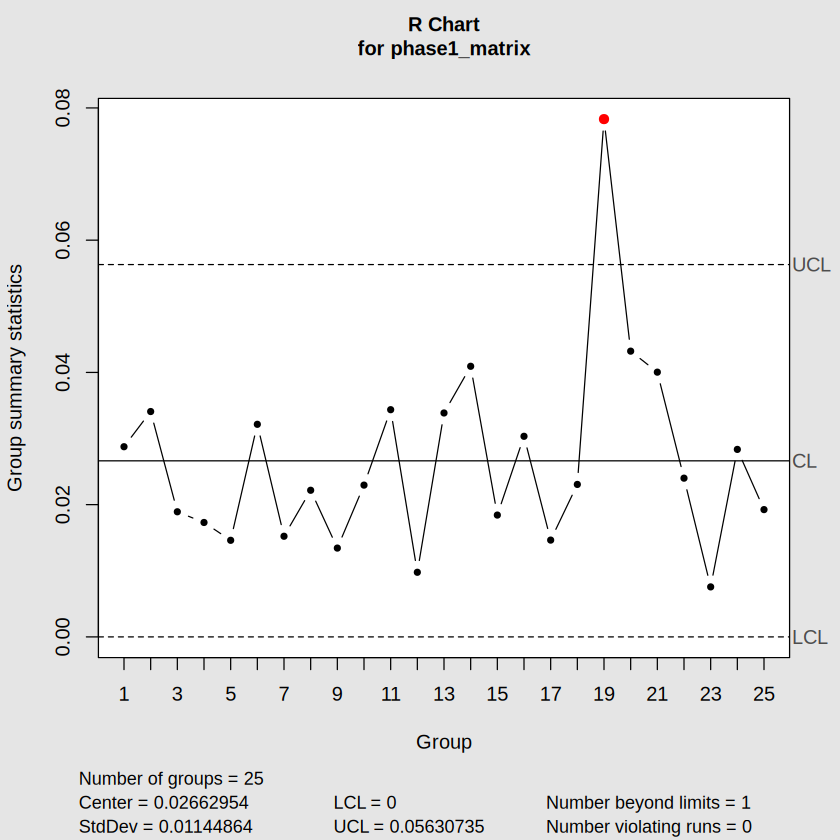

In [7]:
## Q5 Code ##

## Construct and plot the Phase I R chart ##
phase1_R <- qcc(phase1_matrix, type = "R", plot = TRUE)

## View summary statistics and control limits ##
summary(phase1_R)

In [8]:
#Q5 Additional Code ##
## Identify which subgroup(s) are out of control ##
phase1_R$violations$beyond.limits

[1] 19


Call:
qcc(data = phase1_matrix_v2, type = "R", plot = TRUE)

R chart for phase1_matrix_v2 

Summary of group statistics:
       Min.     1st Qu.      Median        Mean     3rd Qu.        Max. 
0.007561105 0.016783802 0.023007221 0.024476200 0.032579380 0.043216160 

Group sample size:  5
Number of groups:  24
Center of group statistics:  0.0244762
Standard deviation:  0.01052287 

Control limits:
 LCL        UCL
   0 0.05175418


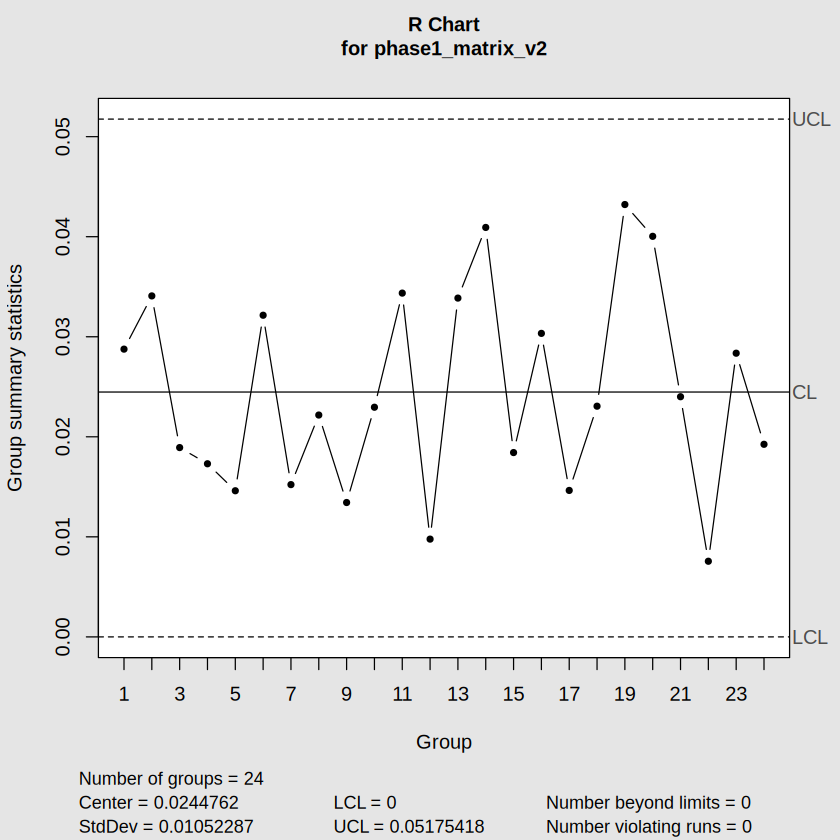

In [9]:
## Q5 Additional Code v2 based on output above ##
## Omit subgroup 19 and reconstruct the R chart ##
phase1_matrix_v2 <- phase1_matrix[-19, ]

phase1_R_v2 <- qcc(phase1_matrix_v2, type = "R", plot = TRUE)

summary(phase1_R_v2)

In [ ]:
# Q5 Interpretation:
# Subgroup 19 was flagged as out of control on the Phase I R chart, with a range far exceeding the upper control limit.
# This suggests unusually high within-subgroup variability for that week's 5 spools with plausibly caused by a temporary process disturbance on Extruder Line 3, such as a brief fluctuation in heating element temperature -> An inconsistency in raw material feed, or a measurement error during that week's sampling.
# Since this point represents a special-cause event rather than typical process variation, it was removed from the baseline calculation.
# After omitting subgroup 19 and reconstructing the chart, all 24 remaining subgroups fall within the revised control limits (LCL = 0, UCL = 0.0518), confirming the R chart now shows statistical control.

### Q6: Using only the subgroups retained after Q5, construct the Phase I $\bar{X}$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control subgroup(s) by number and provide a contextual explanation as to why these OOC points may have been observed, omit these points, and replot the chart until statistical control is observed.


Call:
qcc(data = phase1_matrix_v2, type = "xbar", plot = TRUE)

xbar chart for phase1_matrix_v2 

Summary of group statistics:
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
1.744088 1.750242 1.751436 1.753618 1.752599 1.804824 

Group sample size:  5
Number of groups:  24
Center of group statistics:  1.753618
Standard deviation:  0.01052287 

Control limits:
    LCL      UCL
 1.7395 1.767736


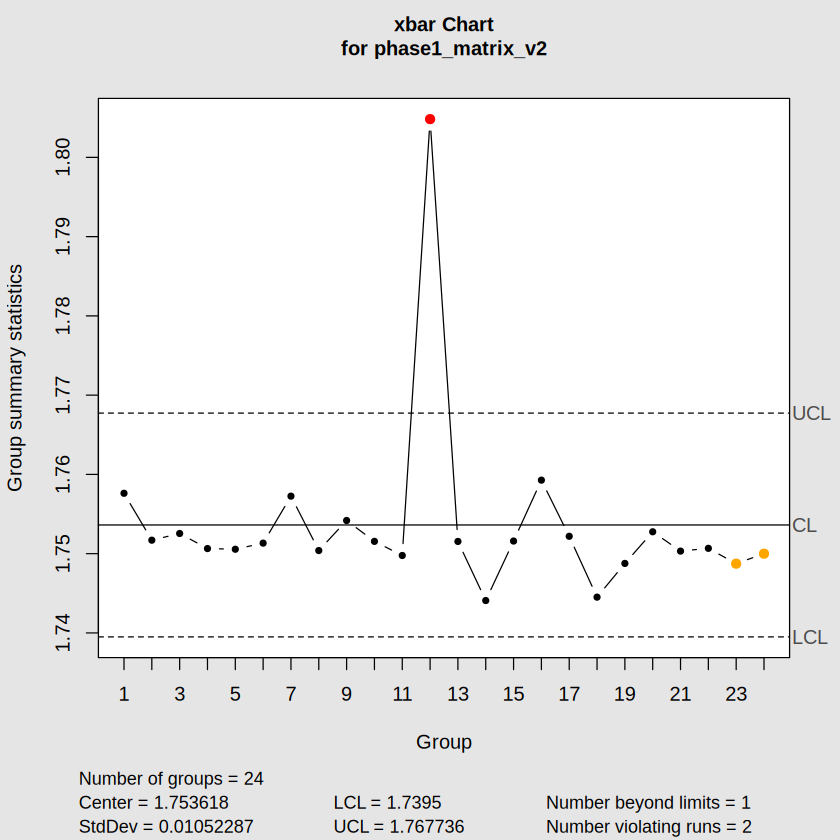

In [10]:
## Q6 Code ##

## Construct and plot the Phase I X-bar chart using retained subgroups ##
phase1_xbar_v2 <- qcc(phase1_matrix_v2, type = "xbar", plot = TRUE)

summary(phase1_xbar_v2)

In [11]:
## Q5 Additonal Code ##
## Identify beyond-limits and run-violation positions in the reduced 24-row data ##
beyond_pos <- phase1_xbar_v2$violations$beyond.limits
runs_pos <- phase1_xbar_v2$violations$violating.runs

## Map back to original subgroup numbers  ##
map_to_original <- function(pos) ifelse(pos < 19, pos, pos + 1)

cat("Beyond limits - original subgroup(s):", map_to_original(beyond_pos), "\n")
cat("Violating runs - original subgroup(s):", map_to_original(runs_pos), "\n")

Beyond limits - original subgroup(s): 12 
Violating runs - original subgroup(s): 24 25 



Call:
qcc(data = phase1_matrix_v3, type = "xbar", plot = TRUE)

xbar chart for phase1_matrix_v3 

Summary of group statistics:
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
1.744088 1.750394 1.751542 1.751585 1.752545 1.759275 

Group sample size:  5
Number of groups:  21
Center of group statistics:  1.751585
Standard deviation:  0.01085145 

Control limits:
      LCL      UCL
 1.737026 1.766144


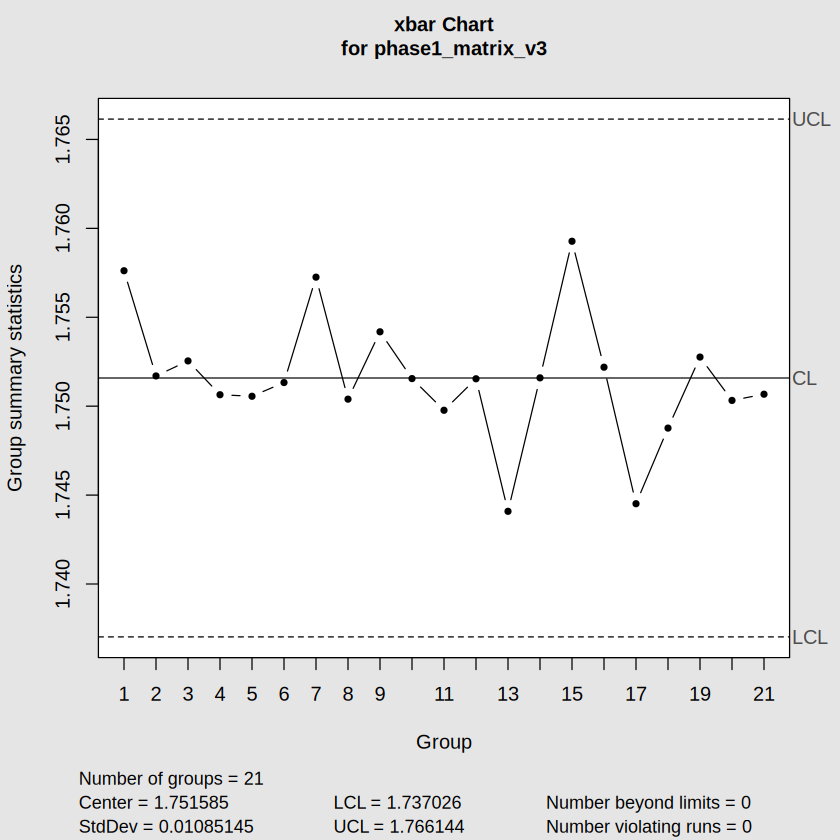

In [12]:
## Q5 Additional Code v2 ##
## Omit subgroup 12 (beyond limits), 24 and 25 (run violation) ##
phase1_matrix_v3 <- phase1_matrix_v2[-c(12, 23, 24), ]

phase1_xbar_v3 <- qcc(phase1_matrix_v3, type = "xbar", plot = TRUE)

summary(phase1_xbar_v3)

In [ ]:
# Q6 Interpretation ##
# Subgroup 12 was flagged as beyond the X̄ chart's control limits, showing an isolated spike likely caused by a one-time disturbance such as a material inconsistency or measurement error.
# Subgroups 24 and 25 triggered a run-rule violation instead, suggesting a sustained shift in the process mean.
# Both of these subgroups were treated as assignable causes and removed.
# After omitting subgroups 12, 24, and 25, the reconstructed chart shows all 21 remaining subgroups within limits, confirming statistical control.

### Q7: Repeat the same process in Q4 - Q6 now using the $s$ chart instead of the $R$ chart

Process mean (unchanged): 1.754 
Estimated process std. dev. (s method): 0.0115 

Call:
qcc(data = phase1_matrix, type = "S", plot = TRUE)

S chart for phase1_matrix 

Summary of group statistics:
       Min.     1st Qu.      Median        Mean     3rd Qu.        Max. 
0.003171372 0.006680901 0.009893827 0.010851993 0.013263603 0.037602024 

Group sample size:  5
Number of groups:  25
Center of group statistics:  0.01085199
Standard deviation:  0.01154485 

Control limits:
 LCL        UCL
   0 0.02266979


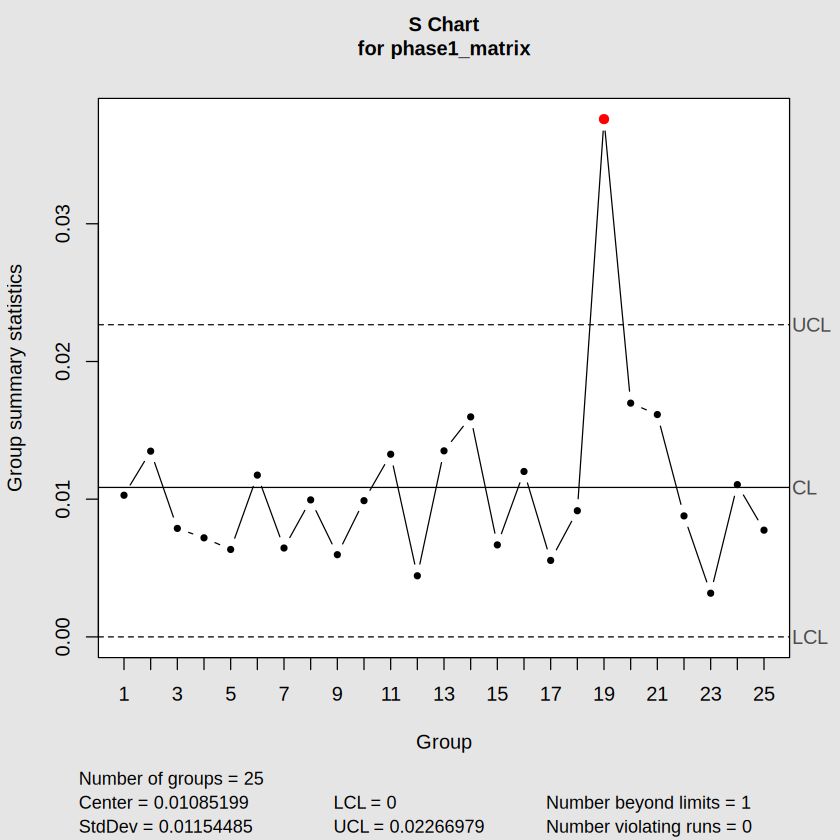

In [13]:
## Q7 Code ##

## Process mean and sigma using the s method (from Q4) ##
cat("Process mean (unchanged):", round(xbarbar, 4), "\n")
cat("Estimated process std. dev. (s method):", round(sigma_s, 4), "\n")

## Construct Phase I s chart ##
phase1_s <- qcc(phase1_matrix, type = "S", plot = TRUE)
summary(phase1_s)

[1] 19


Call:
qcc(data = phase1_matrix_v2s, type = "S", plot = TRUE)

S chart for phase1_matrix_v2s 

Summary of group statistics:
       Min.     1st Qu.      Median        Mean     3rd Qu.        Max. 
0.003171372 0.006624144 0.009528127 0.009737409 0.012324445 0.016976676 

Group sample size:  5
Number of groups:  24
Center of group statistics:  0.009737409
Standard deviation:  0.0103591 

Control limits:
 LCL        UCL
   0 0.02034143


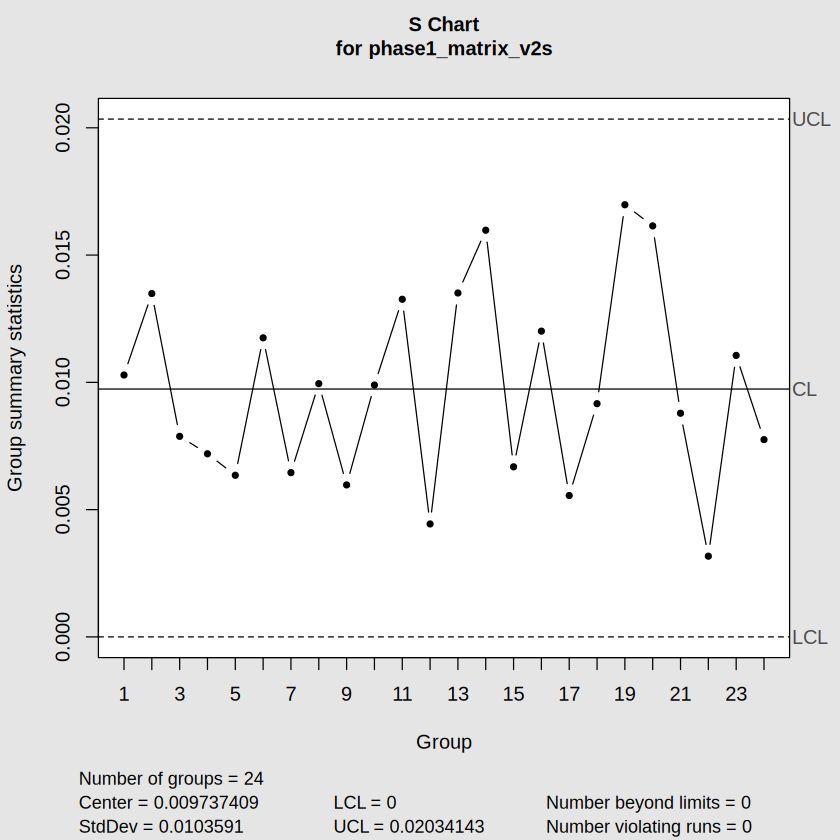

In [14]:
# Q7 Additional Code ##
## Confirm the flagged subgroup ##
phase1_s$violations$beyond.limits

## Omit subgroup 19 and reconstruct the s chart ##
phase1_matrix_v2s <- phase1_matrix[-19, ]

phase1_s_v2 <- qcc(phase1_matrix_v2s, type = "S", plot = TRUE)
summary(phase1_s_v2)

In [ ]:
# Q7 Interpretation based on above output ##
# Consistent with the R chart in Q5, subgroup 19 was flagged as beyond the control limits on the Phase I s chart, reflecting the same unusual spike in within-subgroup variability for that week.
# As before, this was treated as a special cause and removed from the baseline.
# After omitting subgroup 19, the reconstructed s chart shows all 24 remaining subgroups within limits (LCL = 0, UCL = 0.0203), confirming statistical control.


Call:
qcc(data = phase1_matrix_v2s, type = "xbar", std.dev = sigma_s_v2,     plot = TRUE)

xbar chart for phase1_matrix_v2s 

Summary of group statistics:
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
1.744088 1.750242 1.751436 1.753618 1.752599 1.804824 

Group sample size:  5
Number of groups:  24
Center of group statistics:  1.753618
Standard deviation:  0.0103591 

Control limits:
     LCL      UCL
 1.73972 1.767517


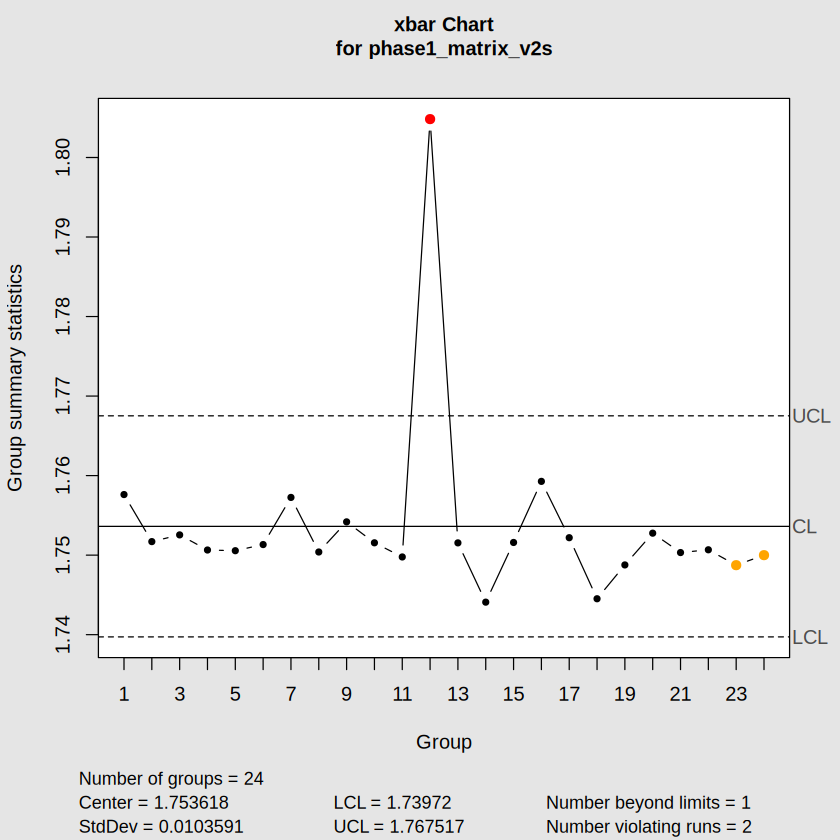

In [15]:
# Q7 Second Half Code ##
## Construct Phase I X-bar chart using s-based sigma, on subgroups retained after S chart ##
sigma_s_v2 <- sd.xbar(phase1_matrix_v2s, std.dev = "UWAVE-SD")

phase1_xbar_s <- qcc(phase1_matrix_v2s, type = "xbar", std.dev = sigma_s_v2, plot = TRUE)
summary(phase1_xbar_s)

In [16]:
## Q7 Additional Code Step ##
## Identify beyond-limits and run-violation positions, mapped to original subgroup numbers ##
beyond_pos_s <- phase1_xbar_s$violations$beyond.limits
runs_pos_s <- phase1_xbar_s$violations$violating.runs

map_to_original <- function(pos) ifelse(pos < 19, pos, pos + 1)

cat("Beyond limits - original subgroup(s):", map_to_original(beyond_pos_s), "\n")
cat("Violating runs - original subgroup(s):", map_to_original(runs_pos_s), "\n")

Beyond limits - original subgroup(s): 12 
Violating runs - original subgroup(s): 24 25 



Call:
qcc(data = phase1_matrix_v3s, type = "xbar", std.dev = sd.xbar(phase1_matrix_v3s,     std.dev = "UWAVE-SD"), plot = TRUE)

xbar chart for phase1_matrix_v3s 

Summary of group statistics:
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
1.744088 1.750394 1.751542 1.751585 1.752545 1.759275 

Group sample size:  5
Number of groups:  21
Center of group statistics:  1.751585
Standard deviation:  0.01066144 

Control limits:
      LCL      UCL
 1.737281 1.765889


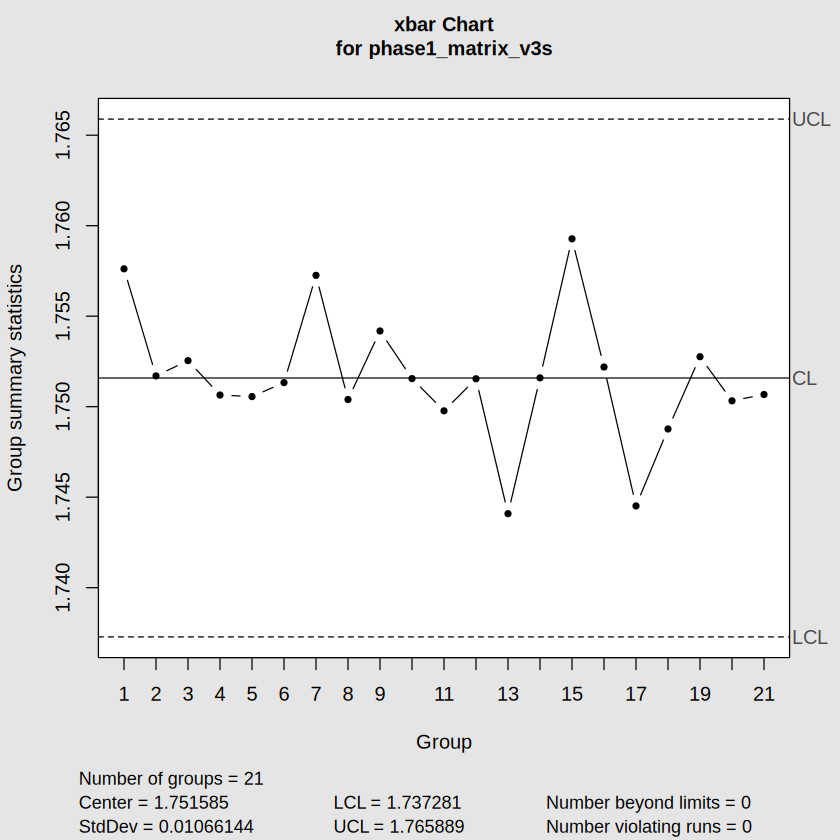

In [17]:
## Q7 Additional Code Step (based on above output) ##
## Omit subgroup 12 (beyond limits) and 24 & 25 (run violation) ##
## Positions relative to phase1_matrix_v2s ##
phase1_matrix_v3s <- phase1_matrix_v2s[-c(12, 23, 24), ]

phase1_xbar_s_v2 <- qcc(phase1_matrix_v3s, type = "xbar", std.dev = sd.xbar(phase1_matrix_v3s, std.dev = "UWAVE-SD"), plot = TRUE)
summary(phase1_xbar_s_v2)

In [ ]:
# Q7 Interpretation ##
# Repeating the analysis with the s method produced the same results as the R method: subgroup 19 was flagged on the Phase I s chart for excessive within-subgroup variability and was removed.
# On the resulting X̄ chart, subgroup 12 was flagged as beyond limits and subgroups 24-25 triggered a run violation, mirroring the R-method results in Q6 — likely reflecting the same one-time disturbance and gradual mean shift.
# After removing subgroups 12, 24, and 25, the reconstructed X̄ chart shows all 21 remaining subgroups within limits (LCL = 1.7373, UCL = 1.7659), confirming statistical control.
# Since the R and s methods produced identical conclusions here, this consistency reinforces confidence in the final Phase I estimates.

### Q8: Using your final Phase I estimates of the process mean and process standard deviation (using $s$ method), perform a process capability analysis against the specification limits given about. Report and interpret $FNC$, $C_p$, $C_{pk}$, and $C_{pm}$. Is the process capable of meeting specification? Is it well-centered?


Process Capability Analysis

Call:
process.capability(object = phase1_xbar_s_v2, spec.limits = c(1.7,     1.8), target = 1.75, std.dev = final_sd, nsigmas = 3)

Number of obs = 105          Target = 1.75
       Center = 1.752           LSL = 1.7
       StdDev = 0.01066         USL = 1.8

Capability indices:

      Value   2.5%  97.5%
Cp    1.563  1.351  1.775
Cp_l  1.613  1.421  1.804
Cp_u  1.514  1.333  1.694
Cp_k  1.514  1.298  1.729
Cpm   1.546  1.335  1.757

Exp<LSL 0%	 Obs<LSL 0%
Exp>USL 0%	 Obs>USL 0%


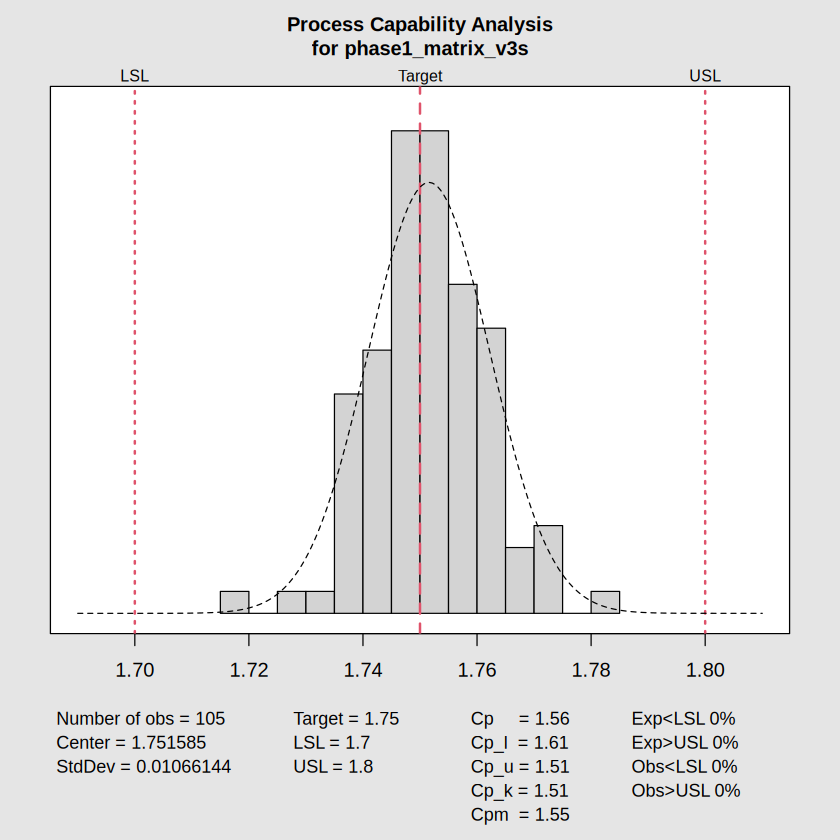

In [18]:
## Q8 Code ##

## Final Phase I estimates from the cleaned s-method chart ##
final_mean <- phase1_xbar_s_v2$center
final_sd <- phase1_xbar_s_v2$std.dev

## Process capability analysis ##
process.capability(phase1_xbar_s_v2,
                   spec.limits = c(1.700, 1.800),
                   target = 1.750,
                   std.dev = final_sd,
                   nsigmas = 3)

In [ ]:
# Q8 Interpretaion ##
# FNC: Since Exp < LSL = 0% and Exp >USL = 0%  total expected FNC is approximately 0%. Essentially, no filament is expected to fall outside the 1.700-1.800mm specification limits, which matches the observed data as well.
# Cp: Cp came out to 1.563. This measures raw process spread against the specification width, ignoring centering. Since Cp exceeds the common 1.33 threshold, the process variability alone is well within what the spec allows.
# Cpk: Cpk came out to 1.514. This is a more realistic measure since it accounts for centering. Cpk is slightly lower than Cp, indicating the process is not perfectly centered on target. Cp_u (1.514) is lower than Cp_l (1.613), meaning there is less margin toward the upper specification limit than the lower one, consistent with the process center (1.752) sitting slightly above the 1.750 target.
# Cpm: Cpm came out to 1.546. This index specifically penalizes deviation from target rather than just the spec midpoint. It falls between Cp and Cpk, confirming the process is close to target but with a small, non-trivial shift.
# Conclusion With Cp = 1.563, Cpk = 1.514, and Cpm = 1.546: The process is highly capable of meeting the 1.700-1.800mm specification, with an expected fraction nonconforming of approximately 0%. The small gap between Cp and Cpk indicates the process is only slightly off-center, with the true center sitting marginally above target. This deviation is minor and does not meaningfully threaten capability.
# Overall, the process is both capable and reasonably well-centered.

## Improve

### Q9: Briefly provide a contextual explanation as to leaving OOC points in the Phase I calculation of the control limits after identifying an assignable cause is not advisable.

## Control

### Q10: Read in the Phase II data into R. Using the finalized Phase I center line and control limits from Q7, construct the Phase II $\bar{X}$ chart. Do any subgroups plot outside the control limits?

In [ ]:
## Q9 Text Answer ##
# Leaving out-of-control points in the Phase I baseline calculation inflates the estimated process mean and standard deviation, since these points reflect assignable causes rather than the process's natural, in-control variation.
# This produces artificially wide control limits that don't accurately represent the process's true stability.
# Once an assignable cause has been identified and addressed, removing the point ensures the baseline reflects only common-cause variation, giving a more accurate and trustworthy picture of the process's actual behavior.


Call:
qcc(data = phase2_matrix, type = "xbar", center = phase1_center,     limits = phase1_limits, plot = TRUE)

xbar chart for phase2_matrix 

Summary of group statistics:
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
1.743002 1.746417 1.748981 1.748609 1.750765 1.755127 

Group sample size:  5
Number of groups:  20
Center of group statistics:  1.751585
Standard deviation:  0.006064431 

Control limits:
     LCL       UCL
 1.737281 1.765889


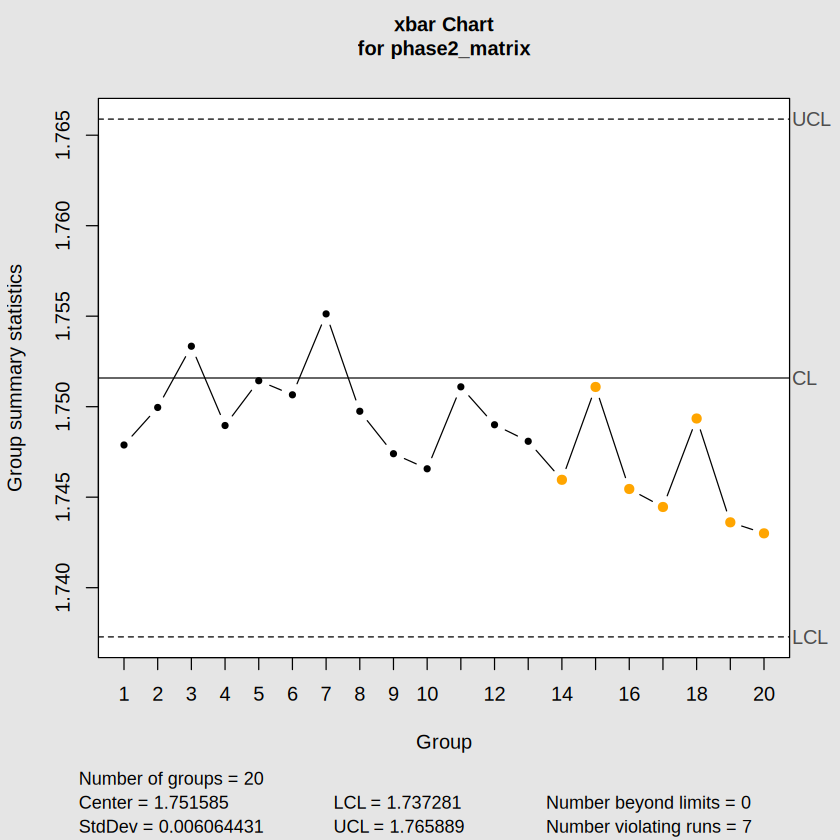

In [21]:
## Q10 Code ##

## Read in the Phase II data ##
phase2_df <- read_excel("STAT-7110-Quality-Control/Assignments/HW1/FilamentDiameter_PhaseII.xlsx")

## Convert to matrix of measurements only ##
phase2_matrix <- phase2_df %>% select(-Subgroup) %>% as.matrix()

## Pull the finalized Phase I center and limits from Q7 (s-method) ##
phase1_center <- phase1_xbar_s_v2$center
phase1_limits <- phase1_xbar_s_v2$limits

## Construct Phase II X-bar chart using Phase I center/limits ##
phase2_xbar <- qcc(phase2_matrix, type = "xbar", center = phase1_center, limits = phase1_limits, plot = TRUE)
summary(phase2_xbar)

In [22]:
## Q10 Additonal Code ##
## Identify exact subgroups violating the run rule ##
phase2_xbar$violations$violating.runs

[1] 14 15 16 17 18 19 20

In [ ]:
## Q10 Interpretation ##
# Using the finalized Phase I center line and control limits, the Phase II X̄ chart shows no individual subgroups plotting beyond the control limits.
# However, the chart flags a run violation across subgroups 14 through 20 — seven consecutive subgroups falling below the center line.
# This sustained downward run indicates the process mean has shifted lower over time, even though no single point is extreme enough to breach the control limits directly.
# This pattern is consistent with the scenario's description of the extrusion line's heating element aging — a gradual decline in filament diameter is exactly what would be expected as the line approaches the point where the heating element needs replacement.

### Q11: Construct a Phase II $s$ chart. Do any subgroups plot outside the control limits?


Call:
qcc(data = phase2_matrix, type = "S", plot = TRUE)

S chart for phase2_matrix 

Summary of group statistics:
       Min.     1st Qu.      Median        Mean     3rd Qu.        Max. 
0.001773705 0.004386042 0.005614758 0.005871178 0.007174237 0.009891207 

Group sample size:  5
Number of groups:  20
Center of group statistics:  0.005871178
Standard deviation:  0.006246029 

Control limits:
 LCL        UCL
   0 0.01226488


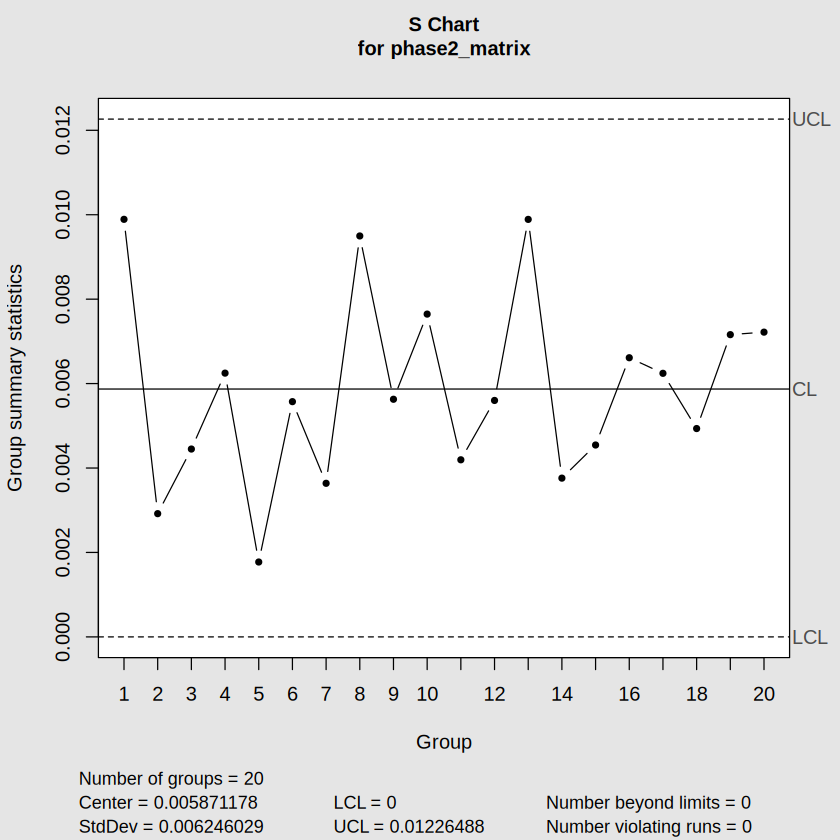

In [23]:
## Q11 Code ##

## Construct Phase II s chart ##
phase2_s <- qcc(phase2_matrix, type = "S", plot = TRUE)

summary(phase2_s)

In [ ]:
## Q11 Interpretation ##
# Unlike the Phase II X̄ chart in Q10, this s chart was built using control limits calculated from the Phase II data itself rather than the finalized Phase I limits from Q7.
# Thus, the Phase II s chart shows no subgroups plotting outside the control limits and no run violations, indicating the process variability remained stable throughout the Phase II monitoring period.

### Q12: Provide an overview of the results that the plant manager can provide the Vice President of Operations. Do they need to completely overhaul line 3 or is it salvagable?

In [ ]:
## Q12 Answer ##
# Phase I analysis confirmed that after removing a small number of assignable-cause outliers, Line 3 operates in statistical control with strong process capability (Cp = 1.563, Cpk = 1.514, Cpm = 1.546).
# Also, it is near-zero expected nonconformance.
# Phase II monitoring showed variability remained stable, but the X̄ chart revealed a sustained downward run across the final seven subgroups.
# No single point breached the limits, but the trend points to a gradual shift in the process mean, consistent with an aging heating element.

# Line 3 does not need a complete overhaul.
# The process itself is fundamentally capable and variability is well-controlled.
# The issue is a drifting mean, not a broken process.
# The recommended action is replacing the heating element sooner than the original six-month timeline, followed by continued monitoring to confirm the mean returns to its established center line.